# 3D Parallelism Power Scaling Analysis

Tests three hypotheses about average steady-state cluster power as the
number of nodes scales from n=2 to n=8 on GPT-2 medium training:

**H1.** The TP-heavy configuration (max valid TP for that n) is the
       *lowest* avg steady-state power at every node count.

**H2.** Pure data parallelism (DP = world size) loses its power advantage
       as nodes scale — its relative rank should drift upward (worse) with n.

**H3.** Balanced PP-DP configurations (DP ≈ PP with TP = 1) become the
       *highest* avg steady-state power as nodes scale.

Reads sidecar `rank*.csv` traces from every successful config under
`power_logs/gpt2_medium_n{N}_<SWEEP_ID>/`.

In [2]:
import os
import re
import glob
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
})

# Color per config category (used consistently in every plot below).
CAT_COLORS = {
    "TP=W":   "#2e7d32",  # green   — max-TP (closest to TP = world size)
    "DP=W":   "#1565c0",  # blue    — pure DP (DP = world size)
    "PP=max": "#ef6c00",  # orange  — max-PP (PP-heavy)
    "DP=PP":  "#c62828",  # red     — balanced DP≈PP with TP=1
    "other":  "#cfd8dc",  # grey    — everything else
}

## Configuration

In [3]:
BASE = Path(os.environ.get(
    "PROJECT_DIR",
    "/bgfs/stephenlee/wat29/scheduling-carbon-aware-3d-parallelism",
))
SWEEP_ID      = "20260512_114447"
MODEL         = "gpt2_medium"
NODE_COUNTS   = [2, 4, 6, 8]
GPUS_PER_NODE = 4

INTERVAL_SECONDS = 0.5    # sidecar sampling interval
WARMUP_FRAC      = 0.20   # drop first 20% of samples for steady-state

PLOTS_DIR = BASE / "plots" / f"{MODEL}_sweep_{SWEEP_ID}"
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Base:       {BASE}")
print(f"Sweep ID:   {SWEEP_ID}")
print(f"Model:      {MODEL}")
print(f"Plots out:  {PLOTS_DIR}")

Base:       /bgfs/stephenlee/wat29/scheduling-carbon-aware-3d-parallelism
Sweep ID:   20260512_114447
Model:      gpt2_medium
Plots out:  /bgfs/stephenlee/wat29/scheduling-carbon-aware-3d-parallelism/plots/gpt2_medium_sweep_20260512_114447


## Load every successful config

In [4]:
CFG_RE = re.compile(r"^tp(\d+)_pp(\d+)_dp(\d+)$")


def parse_cfg(name):
    m = CFG_RE.match(name)
    if not m:
        return None
    tp, pp, dp = map(int, m.groups())
    return {"tp": tp, "pp": pp, "dp": dp, "name": name}


def load_config(cfg_dir):
    """Return cluster power trace by summing every rank*.csv in the folder."""
    rank_files = sorted(glob.glob(str(cfg_dir / "rank*.csv")))
    if not rank_files:
        return None
    series = {}
    for f in rank_files:
        rank = int(re.search(r"rank(\d+)", os.path.basename(f)).group(1))
        df_r = pd.read_csv(f)
        if "total_power_W" not in df_r.columns or len(df_r) < 2:
            continue
        series[rank] = df_r["total_power_W"].to_numpy()
    if not series:
        return None
    n_min = min(len(v) for v in series.values())
    series = {r: v[:n_min] for r, v in series.items()}
    cluster = np.sum(np.stack(list(series.values())), axis=0)
    return {
        "rank_power": series,
        "cluster_power": cluster,
        "time": np.arange(n_min) * INTERVAL_SECONDS,
        "n_ranks": len(series),
    }


records = []
for n in NODE_COUNTS:
    sweep_dir = BASE / "power_logs" / f"{MODEL}_n{n}_{SWEEP_ID}"
    if not sweep_dir.exists():
        print(f"[warn] missing parent folder: {sweep_dir}")
        continue

    print(f"\n--- n={n}: {sweep_dir.name} ---")
    for d in sorted(os.listdir(sweep_dir)):
        cfg_dir = sweep_dir / d
        if not cfg_dir.is_dir():
            continue
        cfg = parse_cfg(d)
        if cfg is None:
            continue

        status_file = cfg_dir / "status.txt"
        status = status_file.read_text().strip() if status_file.exists() else "missing"
        if not status.startswith("OK"):
            print(f"  [skip] {d}: status={status}")
            continue

        data = load_config(cfg_dir)
        if data is None:
            print(f"  [skip] {d}: no usable rank CSVs")
            continue

        p = data["cluster_power"]
        warmup = int(len(p) * WARMUP_FRAC)
        steady = p[warmup:] if len(p) > warmup else p

        records.append({
            "n_nodes":            n,
            "world_size":         n * GPUS_PER_NODE,
            "tp":                 cfg["tp"],
            "pp":                 cfg["pp"],
            "dp":                 cfg["dp"],
            "config":             d,
            "n_ranks":            data["n_ranks"],
            "duration_s":         len(p) * INTERVAL_SECONDS,
            "steady_avg_power_w": float(steady.mean()),
            "peak_power_w":       float(p.max()),
            "energy_wh":          float(p.sum()) * INTERVAL_SECONDS / 3600,
            "_cluster_power":     p,
            "_time":              data["time"],
        })

df = pd.DataFrame(records)
print(f"\nLoaded {len(df)} OK configs across {df['n_nodes'].nunique()} node counts:")
print(df.groupby("n_nodes").size().to_string())


--- n=2: gpt2_medium_n2_20260512_114447 ---

--- n=4: gpt2_medium_n4_20260512_114447 ---

--- n=6: gpt2_medium_n6_20260512_114447 ---
  [skip] tp1_pp8_dp3: status=FAILED rc=1
  [skip] tp2_pp4_dp3: status=FAILED rc=143

--- n=8: gpt2_medium_n8_20260512_114447 ---
  [skip] tp2_pp8_dp2: status=FAILED rc=1
  [skip] tp8_pp4_dp1: status=FAILED rc=1

Loaded 57 OK configs across 4 node counts:
n_nodes
2    10
4    14
6    18
8    15


## Tag each config with a hypothesis category

For each node count:
- **TP=W**: highest TP value present in the valid configs at that n.
  At n=2 and n=4 this literally equals the world size (TP=W). At n=6 and
  n=8 the constraint `HEADS=16 mod TP == 0` caps TP, so we use max-valid-TP.
- **DP=W**: DP equals world size (pure data parallelism).
- **PP=max**: highest PP value present.
- **DP=PP**: TP=1, both PP>1 and DP>1, and |PP - DP| is minimised among
  such configs.

In [5]:
max_tp_per_n = df.groupby("n_nodes")["tp"].max().to_dict()
max_pp_per_n = df.groupby("n_nodes")["pp"].max().to_dict()

print("Max valid TP per node count:", max_tp_per_n)
print("Max valid PP per node count:", max_pp_per_n)


def pick_dp_pp(group):
    cand = group[(group["tp"] == 1) & (group["pp"] > 1) & (group["dp"] > 1)].copy()
    if cand.empty:
        return None
    cand["abs_diff"] = (cand["pp"] - cand["dp"]).abs()
    return cand.sort_values(["abs_diff", "pp"], ascending=[True, False]).iloc[0]["config"]


dp_pp_picks = {n: pick_dp_pp(g) for n, g in df.groupby("n_nodes")}
print("\nDP=PP balanced pick per node count:")
for n, c in dp_pp_picks.items():
    print(f"  n={n}: {c}")


def categorise(row):
    n = row["n_nodes"]
    if row["config"] == dp_pp_picks.get(n):
        return "DP=PP"
    if row["tp"] == max_tp_per_n[n]:
        return "TP=W"
    if row["dp"] == row["world_size"]:
        return "DP=W"
    if row["pp"] == max_pp_per_n[n]:
        return "PP=max"
    return "other"


df["category"] = df.apply(categorise, axis=1)
df["rank"] = df.groupby("n_nodes")["steady_avg_power_w"].rank(method="min").astype(int)
df["n_cfgs_at_n"] = df.groupby("n_nodes")["n_nodes"].transform("count")
df["rank_pct"] = (df["rank"] - 1) / (df["n_cfgs_at_n"] - 1)

print("\nCategory counts:")
print(df["category"].value_counts().to_string())

Max valid TP per node count: {2: 8, 4: 16, 6: 8, 8: 16}
Max valid PP per node count: {2: 8, 4: 8, 6: 24, 8: 8}

DP=PP balanced pick per node count:
  n=2: tp1_pp4_dp2
  n=4: tp1_pp4_dp4
  n=6: tp1_pp6_dp4
  n=8: tp1_pp8_dp4

Category counts:
category
other     38
TP=W       6
PP=max     5
DP=W       4
DP=PP      4


## Plot 1 — Ranked power per node count

For each n, every config sorted ascending by avg steady-state power.
Key categories are labelled above their bars. **Direct test of H1**:
if TP=W is the leftmost bar in all four panels, H1 holds.

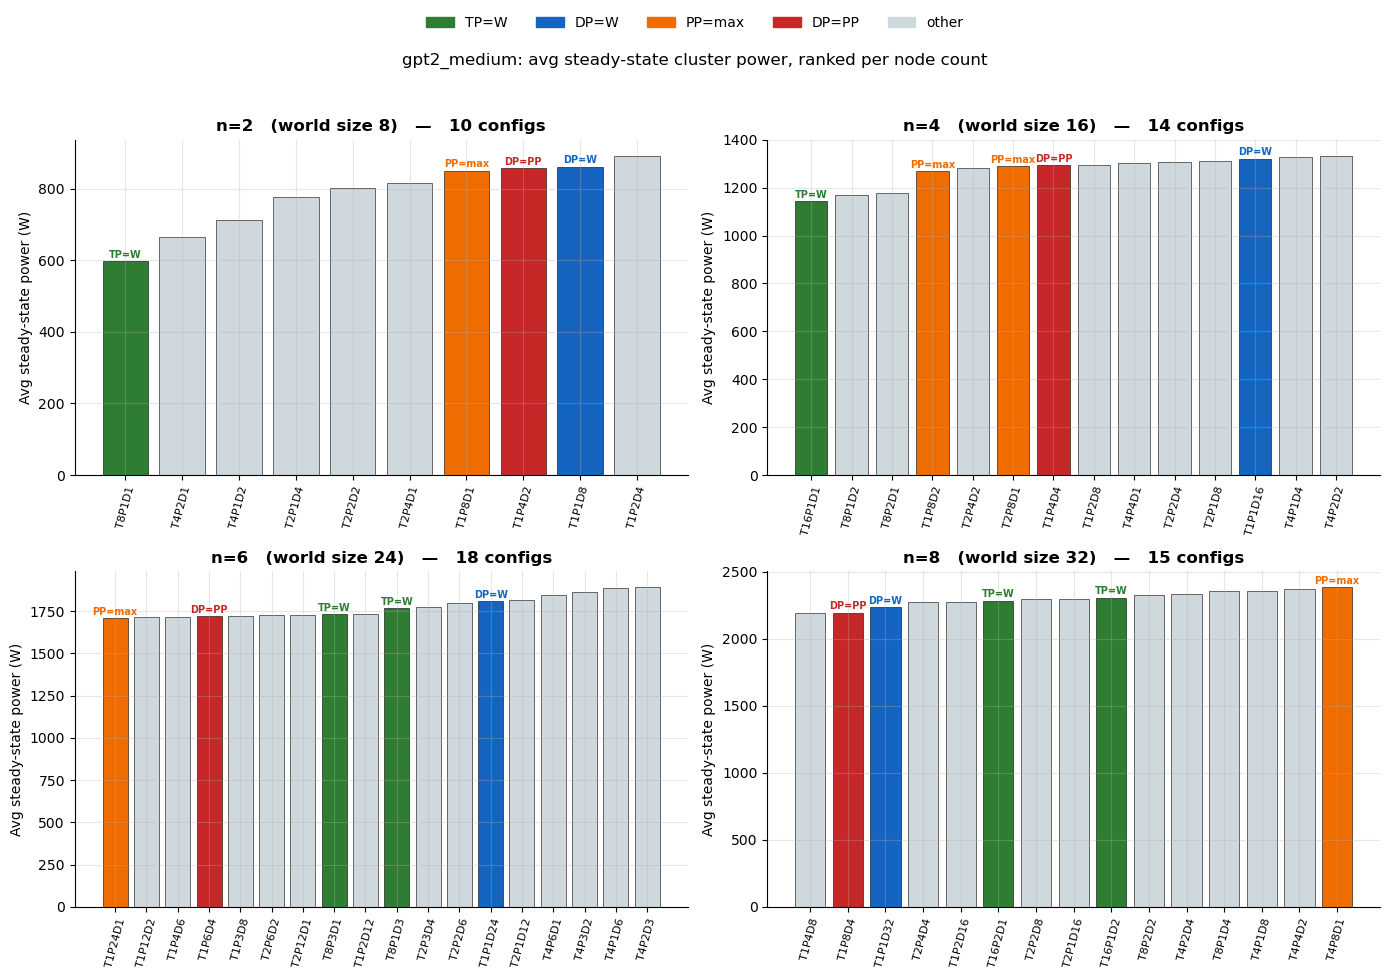

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharey=False)
axes = axes.flatten()

for ax, n in zip(axes, NODE_COUNTS):
    sub = df[df["n_nodes"] == n].sort_values("steady_avg_power_w").reset_index(drop=True)
    if sub.empty:
        ax.set_title(f"n={n}: no data")
        continue

    colors = [CAT_COLORS[c] for c in sub["category"]]
    labels = [f"T{r.tp}P{r.pp}D{r.dp}" for r in sub.itertuples()]

    ax.bar(range(len(sub)), sub["steady_avg_power_w"], color=colors,
           edgecolor="black", linewidth=0.4)
    ax.set_xticks(range(len(sub)))
    ax.set_xticklabels(labels, rotation=75, fontsize=8)
    ax.set_ylabel("Avg steady-state power (W)")
    ax.set_title(f"n={n}   (world size {n * GPUS_PER_NODE})   —   {len(sub)} configs",
                 fontweight="bold")

    for i, (_, r) in enumerate(sub.iterrows()):
        if r["category"] in {"TP=W", "DP=W", "PP=max", "DP=PP"}:
            ax.text(i, r["steady_avg_power_w"] * 1.005,
                    r["category"], ha="center", va="bottom", fontsize=7,
                    color=CAT_COLORS[r["category"]], fontweight="bold")

handles = [mpatches.Patch(color=v, label=k) for k, v in CAT_COLORS.items()]
fig.legend(handles=handles, loc="upper center", ncol=5,
           bbox_to_anchor=(0.5, 0.98), frameon=False)
fig.suptitle(f"{MODEL}: avg steady-state cluster power, ranked per node count", y=0.93)
plt.tight_layout(rect=[0, 0, 1, 0.91])
plt.savefig(PLOTS_DIR / "01_ranked_power_per_n.png", dpi=120, bbox_inches="tight")
plt.show()

## Plot 2 — Scaling of key strategies (absolute power)

X = node count, Y = avg steady-state cluster power, one coloured line per
category. Grey band shows min-to-max spread of all configs at each n.

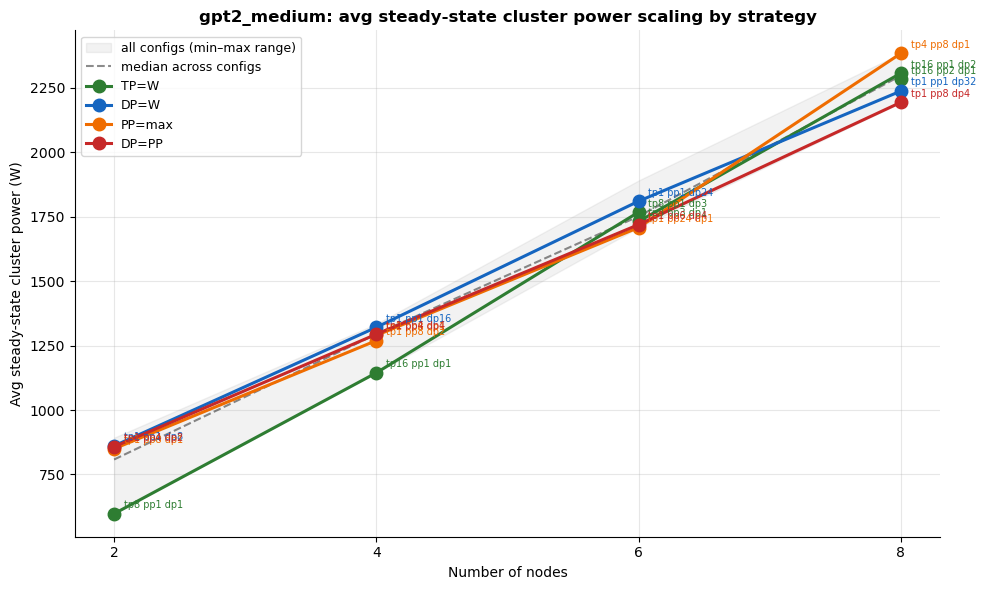

In [7]:
fig, ax = plt.subplots(figsize=(10, 6))

agg = df.groupby("n_nodes")["steady_avg_power_w"].agg(["min", "max", "median"])
ax.fill_between(agg.index, agg["min"], agg["max"], color="gray", alpha=0.10,
                label="all configs (min–max range)")
ax.plot(agg.index, agg["median"], color="black", linestyle="--", alpha=0.45,
        label="median across configs")

for cat in ["TP=W", "DP=W", "PP=max", "DP=PP"]:
    sub = df[df["category"] == cat].sort_values("n_nodes")
    if sub.empty:
        continue
    ax.plot(sub["n_nodes"], sub["steady_avg_power_w"], "o-",
            color=CAT_COLORS[cat], label=cat, linewidth=2.2, markersize=9)
    for _, r in sub.iterrows():
        ax.annotate(r["config"].replace("_", " "),
                    xy=(r["n_nodes"], r["steady_avg_power_w"]),
                    xytext=(7, 4), textcoords="offset points", fontsize=7,
                    color=CAT_COLORS[cat])

ax.set_xlabel("Number of nodes")
ax.set_ylabel("Avg steady-state cluster power (W)")
ax.set_xticks(NODE_COUNTS)
ax.set_title(f"{MODEL}: avg steady-state cluster power scaling by strategy",
             fontweight="bold")
ax.legend(loc="best", fontsize=9)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "02_scaling_absolute.png", dpi=120, bbox_inches="tight")
plt.show()

## Plot 3 — Scaling of relative rank (0 = lowest power, 1 = highest)

**Direct test of all three hypotheses.** Within each n, configs are ranked
ascending by avg steady-state power and mapped onto [0, 1].
- H1: TP=W line should sit at 0.
- H2: DP=W line should rise with n.
- H3: DP=PP line should rise toward 1.

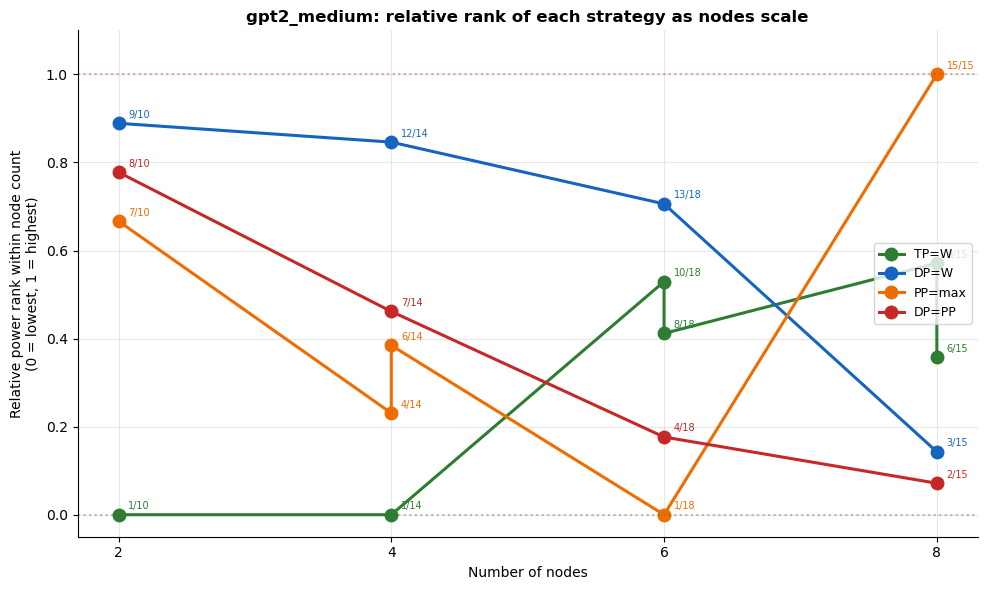

In [8]:
fig, ax = plt.subplots(figsize=(10, 6))

for cat in ["TP=W", "DP=W", "PP=max", "DP=PP"]:
    sub = df[df["category"] == cat].sort_values("n_nodes")
    if sub.empty:
        continue
    ax.plot(sub["n_nodes"], sub["rank_pct"], "o-",
            color=CAT_COLORS[cat], label=cat, linewidth=2.2, markersize=9)
    for _, r in sub.iterrows():
        ax.annotate(f"{int(r['rank'])}/{int(r['n_cfgs_at_n'])}",
                    xy=(r["n_nodes"], r["rank_pct"]),
                    xytext=(7, 4), textcoords="offset points", fontsize=7,
                    color=CAT_COLORS[cat])

ax.axhline(0.0, color=CAT_COLORS["TP=W"], linestyle=":", alpha=0.4)
ax.axhline(1.0, color=CAT_COLORS["DP=PP"], linestyle=":", alpha=0.4)
ax.set_xlabel("Number of nodes")
ax.set_ylabel("Relative power rank within node count\n(0 = lowest, 1 = highest)")
ax.set_xticks(NODE_COUNTS)
ax.set_ylim(-0.05, 1.10)
ax.set_title(f"{MODEL}: relative rank of each strategy as nodes scale",
             fontweight="bold")
ax.legend(loc="center right", fontsize=9)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "03_scaling_rank.png", dpi=120, bbox_inches="tight")
plt.show()

## Plot 4 — Sample cluster power traces (key configs, post-warmup)

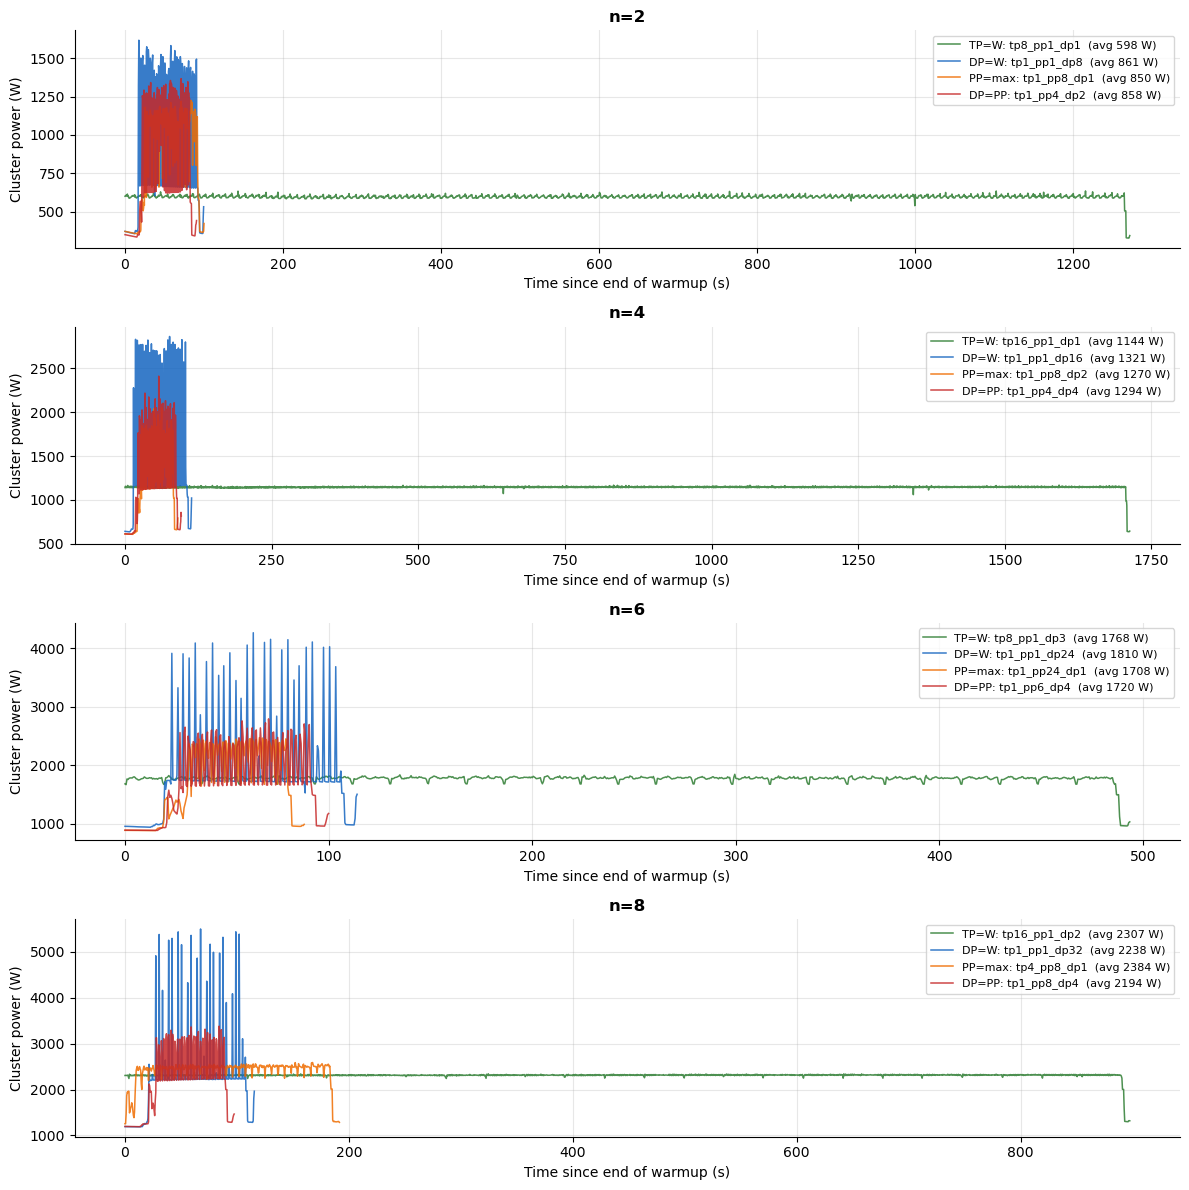

In [9]:
fig, axes = plt.subplots(len(NODE_COUNTS), 1, figsize=(12, 3 * len(NODE_COUNTS)))
if len(NODE_COUNTS) == 1:
    axes = [axes]

for ax, n in zip(axes, NODE_COUNTS):
    sub = df[df["n_nodes"] == n]
    plotted_any = False
    for cat in ["TP=W", "DP=W", "PP=max", "DP=PP"]:
        s = sub[sub["category"] == cat]
        if s.empty:
            continue
        row = s.iloc[0]
        p = row["_cluster_power"]
        t = row["_time"]
        warmup = int(len(p) * WARMUP_FRAC)
        t_steady, p_steady = t[warmup:] - t[warmup], p[warmup:]
        ax.plot(t_steady, p_steady, color=CAT_COLORS[cat],
                label=f"{cat}: {row['config']}  (avg {row['steady_avg_power_w']:.0f} W)",
                linewidth=1.1, alpha=0.85)
        plotted_any = True

    ax.set_title(f"n={n}", fontweight="bold")
    ax.set_xlabel("Time since end of warmup (s)")
    ax.set_ylabel("Cluster power (W)")
    if plotted_any:
        ax.legend(fontsize=8, loc="best")

plt.tight_layout()
plt.savefig(PLOTS_DIR / "04_traces_key_configs.png", dpi=120, bbox_inches="tight")
plt.show()

## Summary tables

In [10]:
key_rows = []
for n in NODE_COUNTS:
    sub = df[df["n_nodes"] == n]
    if sub.empty:
        continue
    actual_min = sub.sort_values("steady_avg_power_w").iloc[0]
    actual_max = sub.sort_values("steady_avg_power_w").iloc[-1]
    for cat in ["TP=W", "DP=W", "PP=max", "DP=PP"]:
        s = sub[sub["category"] == cat]
        if s.empty:
            continue
        r = s.iloc[0]
        key_rows.append({
            "n_nodes":         n,
            "world_size":      n * GPUS_PER_NODE,
            "category":        cat,
            "config":          r["config"],
            "avg_steady_W":    round(r["steady_avg_power_w"], 1),
            "rank":            int(r["rank"]),
            "of_n_configs":    int(r["n_cfgs_at_n"]),
            "rank_pct":        round(r["rank_pct"], 2),
            "is_global_min":   r["config"] == actual_min["config"],
            "is_global_max":   r["config"] == actual_max["config"],
        })

key_summary = pd.DataFrame(key_rows)
print("\nKey-configuration summary:")
print(key_summary.to_string(index=False))
key_summary.to_csv(PLOTS_DIR / "summary_key_configs.csv", index=False)

full = df.drop(columns=["_cluster_power", "_time"]).copy()
full.to_csv(PLOTS_DIR / "summary_all_configs.csv", index=False)
print(f"\nSaved tables and plots under {PLOTS_DIR}")


Key-configuration summary:
 n_nodes  world_size category       config  avg_steady_W  rank  of_n_configs  rank_pct  is_global_min  is_global_max
       2           8     TP=W  tp8_pp1_dp1         597.6     1            10      0.00           True          False
       2           8     DP=W  tp1_pp1_dp8         860.8     9            10      0.89          False          False
       2           8   PP=max  tp1_pp8_dp1         849.7     7            10      0.67          False          False
       2           8    DP=PP  tp1_pp4_dp2         857.5     8            10      0.78          False          False
       4          16     TP=W tp16_pp1_dp1        1144.5     1            14      0.00           True          False
       4          16     DP=W tp1_pp1_dp16        1321.1    12            14      0.85          False          False
       4          16   PP=max  tp1_pp8_dp2        1269.6     4            14      0.23          False          False
       4          16    DP=PP  tp1_p

## Hypothesis evaluation (programmatic)

In [11]:
print("=" * 78)
print("H1: TP=W (max-TP) is the lowest avg steady-state power at each n")
print("=" * 78)
for n in NODE_COUNTS:
    sub = df[df["n_nodes"] == n].sort_values("steady_avg_power_w")
    if sub.empty:
        continue
    tp_w = sub[sub["category"] == "TP=W"]
    if tp_w.empty:
        print(f"  n={n}: no TP=W config detected (skipped)")
        continue
    actual_min = sub.iloc[0]
    r = tp_w.iloc[0]
    verdict = "HOLDS" if r["config"] == actual_min["config"] else "FAILS"
    print(f"  n={n}:   actual min = {actual_min['config']:>16s} "
          f"({actual_min['steady_avg_power_w']:6.0f} W)   "
          f"TP=W = {r['config']:>16s} "
          f"({r['steady_avg_power_w']:6.0f} W, rank {int(r['rank'])}/{int(r['n_cfgs_at_n'])})"
          f"   → {verdict}")

print()
print("=" * 78)
print("H2: DP=W (pure DP) loses its power advantage as n grows")
print("    (rank_pct should rise toward 1 with n)")
print("=" * 78)
dp_w = df[df["category"] == "DP=W"].sort_values("n_nodes")
prev_pct = None
for _, r in dp_w.iterrows():
    delta = "" if prev_pct is None else f"  Δ={r['rank_pct'] - prev_pct:+.2f}"
    print(f"  n={int(r['n_nodes'])}: {r['config']:>16s} "
          f"({r['steady_avg_power_w']:6.0f} W)   "
          f"rank {int(r['rank']):2d}/{int(r['n_cfgs_at_n'])}   "
          f"rank_pct={r['rank_pct']:.2f}{delta}")
    prev_pct = r["rank_pct"]

print()
print("=" * 78)
print("H3: DP=PP (balanced DP≈PP, TP=1) becomes the highest power as n grows")
print("    (rank_pct should rise toward 1 with n)")
print("=" * 78)
dp_pp = df[df["category"] == "DP=PP"].sort_values("n_nodes")
prev_pct = None
for _, r in dp_pp.iterrows():
    delta = "" if prev_pct is None else f"  Δ={r['rank_pct'] - prev_pct:+.2f}"
    print(f"  n={int(r['n_nodes'])}: {r['config']:>16s} "
          f"({r['steady_avg_power_w']:6.0f} W)   "
          f"rank {int(r['rank']):2d}/{int(r['n_cfgs_at_n'])}   "
          f"rank_pct={r['rank_pct']:.2f}{delta}")
    prev_pct = r["rank_pct"]

print()
print("=" * 78)
print("Cross-strategy ordering at each n  (lowest → highest avg steady power)")
print("=" * 78)
for n in NODE_COUNTS:
    sub = df[df["n_nodes"] == n].sort_values("steady_avg_power_w")
    if sub.empty:
        continue
    keys = sub[sub["category"].isin(["TP=W", "DP=W", "PP=max", "DP=PP"])]
    chain = "  <  ".join(
        f"{r['category']}({r['steady_avg_power_w']:.0f}W)" for _, r in keys.iterrows()
    )
    print(f"  n={n}: {chain}")

H1: TP=W (max-TP) is the lowest avg steady-state power at each n
  n=2:   actual min =      tp8_pp1_dp1 (   598 W)   TP=W =      tp8_pp1_dp1 (   598 W, rank 1/10)   → HOLDS
  n=4:   actual min =     tp16_pp1_dp1 (  1144 W)   TP=W =     tp16_pp1_dp1 (  1144 W, rank 1/14)   → HOLDS
  n=6:   actual min =     tp1_pp24_dp1 (  1708 W)   TP=W =      tp8_pp3_dp1 (  1732 W, rank 8/18)   → FAILS
  n=8:   actual min =      tp1_pp4_dp8 (  2193 W)   TP=W =     tp16_pp2_dp1 (  2283 W, rank 6/15)   → FAILS

H2: DP=W (pure DP) loses its power advantage as n grows
    (rank_pct should rise toward 1 with n)
  n=2:      tp1_pp1_dp8 (   861 W)   rank  9/10   rank_pct=0.89
  n=4:     tp1_pp1_dp16 (  1321 W)   rank 12/14   rank_pct=0.85  Δ=-0.04
  n=6:     tp1_pp1_dp24 (  1810 W)   rank 13/18   rank_pct=0.71  Δ=-0.14
  n=8:     tp1_pp1_dp32 (  2238 W)   rank  3/15   rank_pct=0.14  Δ=-0.56

H3: DP=PP (balanced DP≈PP, TP=1) becomes the highest power as n grows
    (rank_pct should rise toward 1 with n)
  n=2:

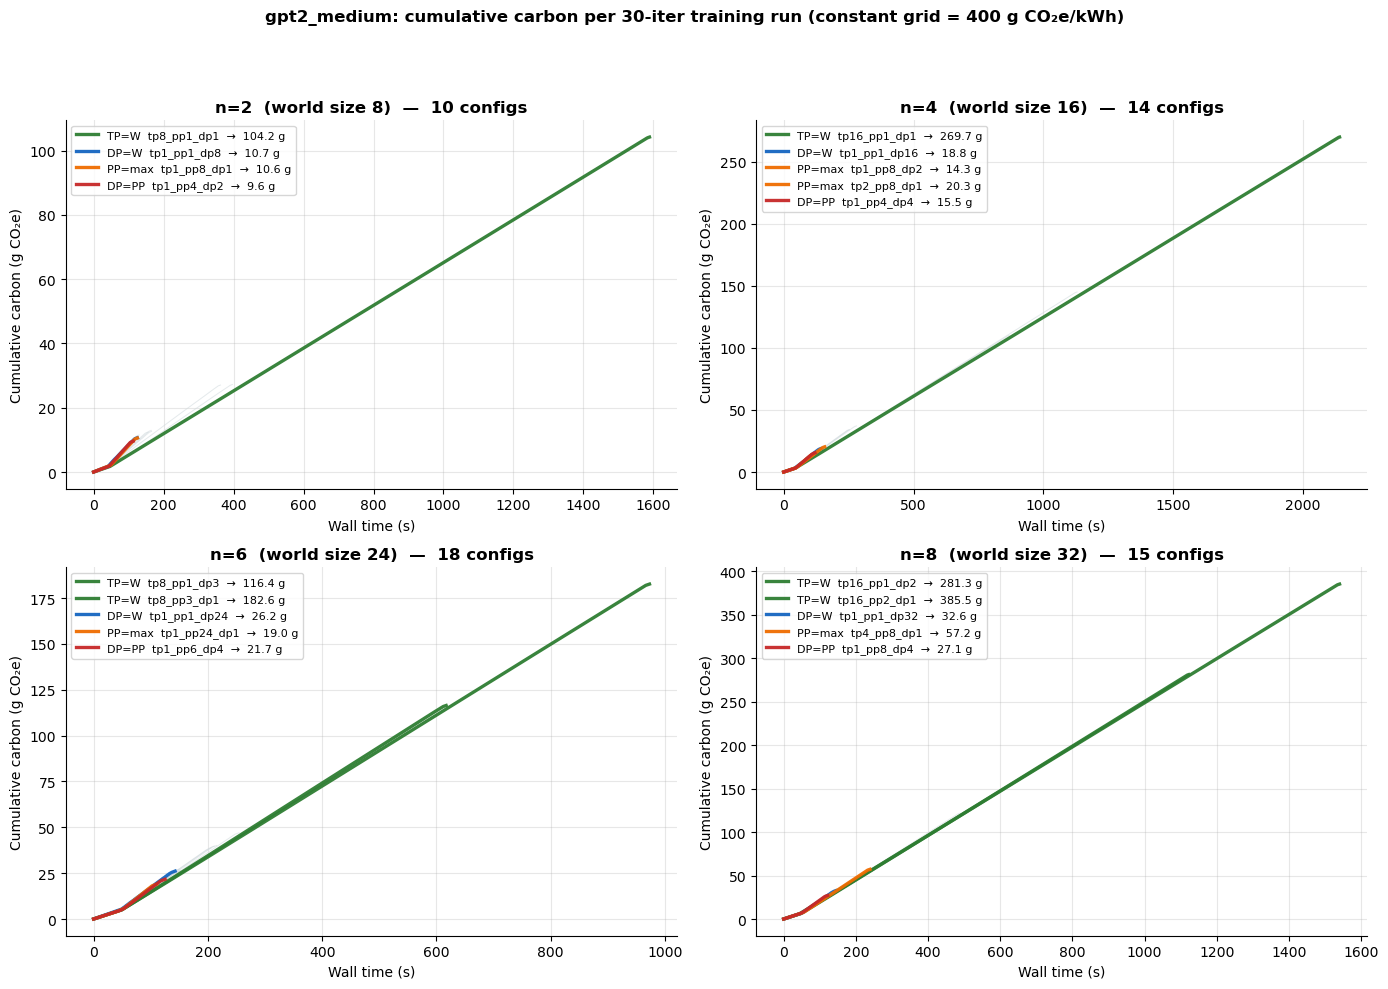


Total carbon per 30-iter run — key configurations:
 n_nodes category       config  duration_s  avg_power_W  total_gCO2e
       2    DP=PP  tp1_pp4_dp2       113.5        857.5         9.59
       2   PP=max  tp1_pp8_dp1       125.5        849.7        10.58
       2     DP=W  tp1_pp1_dp8       125.0        860.8        10.66
       2     TP=W  tp8_pp1_dp1      1589.5        597.6       104.22
       4   PP=max  tp1_pp8_dp2       113.0       1269.6        14.30
       4    DP=PP  tp1_pp4_dp4       120.5       1294.2        15.52
       4     DP=W tp1_pp1_dp16       142.5       1321.1        18.81
       4   PP=max  tp2_pp8_dp1       158.0       1289.6        20.27
       4     TP=W tp16_pp1_dp1      2141.5       1144.5       269.74
       6   PP=max tp1_pp24_dp1       110.5       1708.2        18.98
       6    DP=PP  tp1_pp6_dp4       125.5       1719.6        21.69
       6     DP=W tp1_pp1_dp24       143.0       1810.5        26.15
       6     TP=W  tp8_pp1_dp3       617.5       17

In [12]:
# %% [markdown]
# ## Plot 5 — Cumulative carbon over the run
#
# X = wall time (s). Y = running gCO₂e, computed from the cluster power
# trace times a constant grid intensity (400 gCO₂e / kWh).
#
# Final value of each line = total carbon for that config's 30-iter run.
# Lines that end earlier ran faster; lines that climb steeply drew more power.
# Greys in the background are the "other" configs (faded for context).

# %%
CARBON_INTENSITY_G_PER_KWH = 400.0
# 1 W × 1 s = 1 J = 1/3_600_000 kWh
CARBON_FACTOR = CARBON_INTENSITY_G_PER_KWH / 3_600_000   # multiply W·s → gCO₂e

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for ax, n in zip(axes, NODE_COUNTS):
    sub = df[df["n_nodes"] == n]
    if sub.empty:
        ax.set_title(f"n={n}: no data")
        continue

    # Background: every "other" config in faded grey for context
    for _, r in sub[sub["category"] == "other"].iterrows():
        cum = np.cumsum(r["_cluster_power"]) * INTERVAL_SECONDS * CARBON_FACTOR
        ax.plot(r["_time"], cum, color=CAT_COLORS["other"],
                linewidth=0.7, alpha=0.55)

    # Foreground: the four key categories in full colour
    for cat in ["TP=W", "DP=W", "PP=max", "DP=PP"]:
        s = sub[sub["category"] == cat]
        for _, r in s.iterrows():
            cum = np.cumsum(r["_cluster_power"]) * INTERVAL_SECONDS * CARBON_FACTOR
            ax.plot(r["_time"], cum, color=CAT_COLORS[cat],
                    linewidth=2.4, alpha=0.95,
                    label=f"{cat}  {r['config']}  →  {cum[-1]:.1f} g")

    ax.set_xlabel("Wall time (s)")
    ax.set_ylabel("Cumulative carbon (g CO₂e)")
    ax.set_title(f"n={n}  (world size {n * GPUS_PER_NODE})  —  {len(sub)} configs",
                 fontweight="bold")
    ax.legend(fontsize=8, loc="upper left")

fig.suptitle(f"{MODEL}: cumulative carbon per 30-iter training run "
             f"(constant grid = {CARBON_INTENSITY_G_PER_KWH:.0f} g CO₂e/kWh)",
             y=0.985, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.savefig(PLOTS_DIR / "05_cumulative_carbon.png", dpi=120, bbox_inches="tight")
plt.show()

# Quick total-carbon summary table (key configs only)
rows = []
for _, r in df[df["category"].isin(["TP=W", "DP=W", "PP=max", "DP=PP"])].iterrows():
    total_g = float(np.sum(r["_cluster_power"]) * INTERVAL_SECONDS * CARBON_FACTOR)
    rows.append({
        "n_nodes":     r["n_nodes"],
        "category":    r["category"],
        "config":      r["config"],
        "duration_s":  round(r["duration_s"], 1),
        "avg_power_W": round(r["steady_avg_power_w"], 1),
        "total_gCO2e": round(total_g, 2),
    })
carbon_summary = pd.DataFrame(rows).sort_values(["n_nodes", "total_gCO2e"])
print("\nTotal carbon per 30-iter run — key configurations:")
print(carbon_summary.to_string(index=False))
carbon_summary.to_csv(PLOTS_DIR / "summary_carbon_key_configs.csv", index=False)

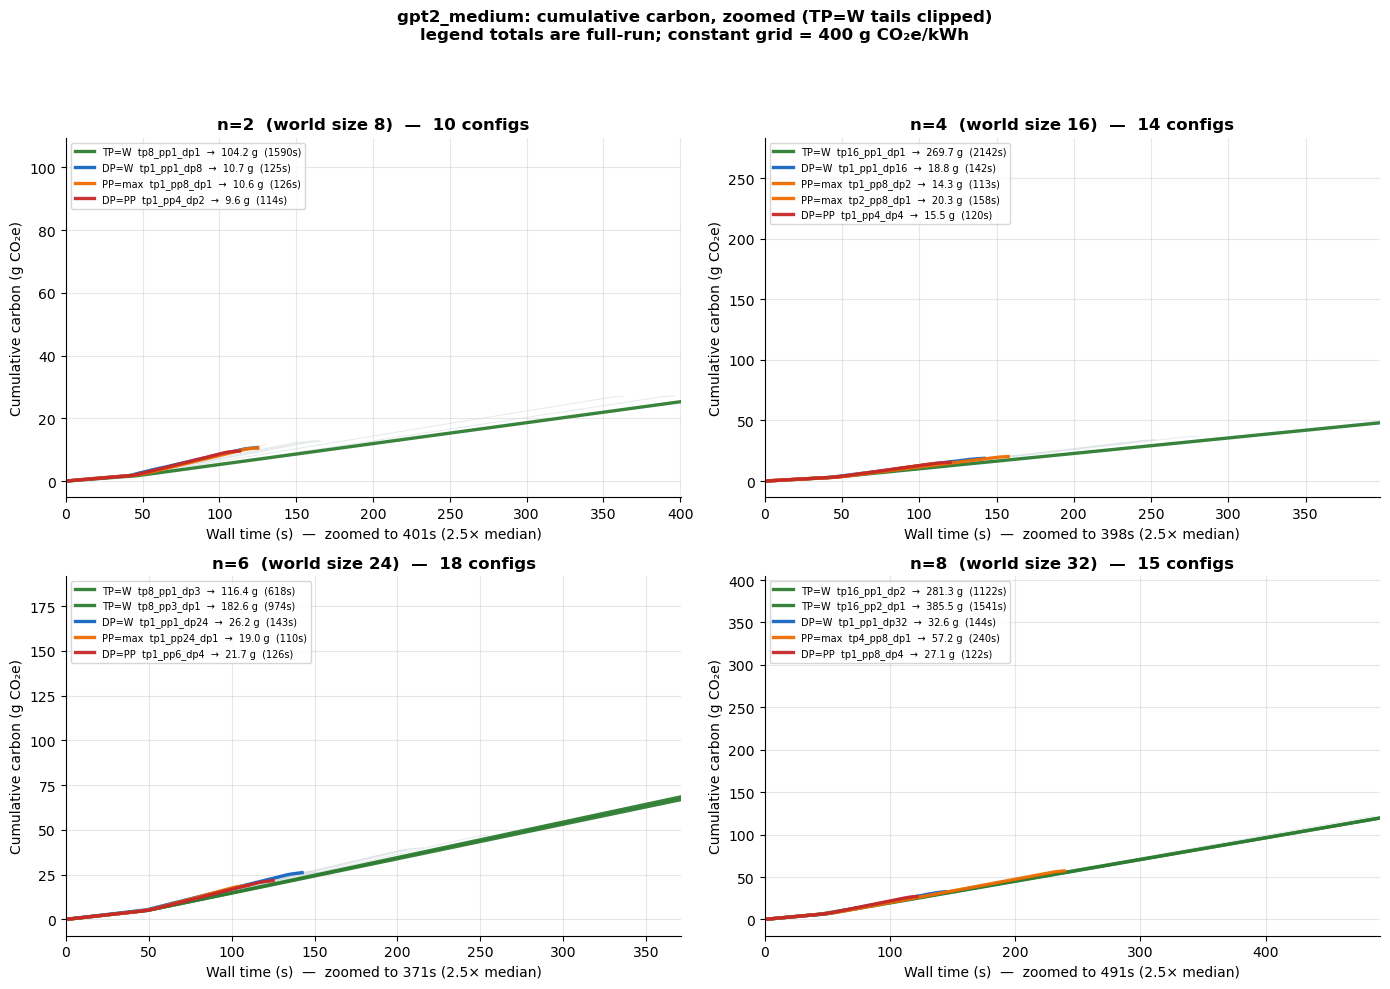

In [13]:
# %% [markdown]
# ## Plot 5b — Cumulative carbon, zoomed
# X-axis clipped to 2.5× the median duration at each n, so the long
# TP=W tails are cropped and we can see the other configs.
# Legend totals are still full-run.

# %%
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for ax, n in zip(axes, NODE_COUNTS):
    sub = df[df["n_nodes"] == n]
    if sub.empty:
        ax.set_title(f"n={n}: no data")
        continue

    x_max = sub["duration_s"].median() * 2.5

    for _, r in sub[sub["category"] == "other"].iterrows():
        cum = np.cumsum(r["_cluster_power"]) * INTERVAL_SECONDS * CARBON_FACTOR
        ax.plot(r["_time"], cum, color=CAT_COLORS["other"], linewidth=0.7, alpha=0.55)

    for cat in ["TP=W", "DP=W", "PP=max", "DP=PP"]:
        s = sub[sub["category"] == cat]
        for _, r in s.iterrows():
            cum = np.cumsum(r["_cluster_power"]) * INTERVAL_SECONDS * CARBON_FACTOR
            ax.plot(r["_time"], cum, color=CAT_COLORS[cat], linewidth=2.4, alpha=0.95,
                    label=f"{cat}  {r['config']}  →  {cum[-1]:.1f} g  "
                          f"({r['duration_s']:.0f}s)")

    ax.set_xlim(0, x_max)
    ax.set_xlabel(f"Wall time (s)  —  zoomed to {x_max:.0f}s (2.5× median)")
    ax.set_ylabel("Cumulative carbon (g CO₂e)")
    ax.set_title(f"n={n}  (world size {n * GPUS_PER_NODE})  —  {len(sub)} configs",
                 fontweight="bold")
    ax.legend(fontsize=7, loc="upper left")

fig.suptitle(f"{MODEL}: cumulative carbon, zoomed (TP=W tails clipped)\n"
             f"legend totals are full-run; constant grid = "
             f"{CARBON_INTENSITY_G_PER_KWH:.0f} g CO₂e/kWh",
             y=0.985, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.savefig(PLOTS_DIR / "05b_cumulative_carbon_zoomed.png", dpi=120, bbox_inches="tight")
plt.show()

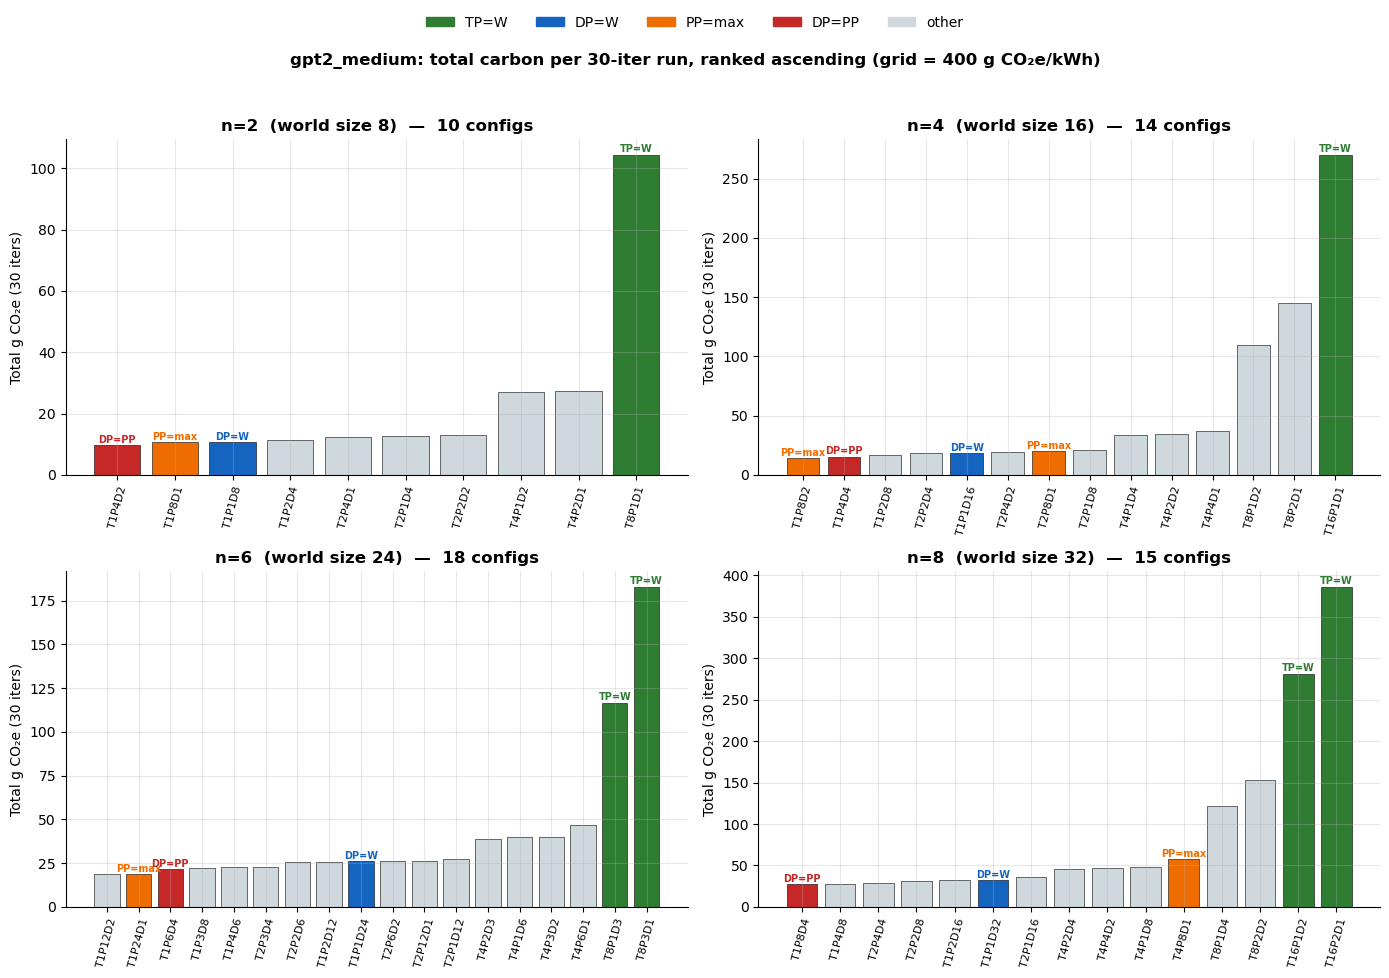

In [14]:
# %% [markdown]
# ## Plot 6 — Total carbon per 30-iter run, ranked ascending
# Final endpoint of each line in Plot 5, sorted. The picture that
# Plot 1 (ranked steady-state power) should be compared against.

# %%
df["total_gco2e"] = df["_cluster_power"].apply(
    lambda p: float(np.sum(p) * INTERVAL_SECONDS * CARBON_FACTOR)
)

fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharey=False)
axes = axes.flatten()

for ax, n in zip(axes, NODE_COUNTS):
    sub = df[df["n_nodes"] == n].sort_values("total_gco2e").reset_index(drop=True)
    if sub.empty:
        ax.set_title(f"n={n}: no data")
        continue

    colors = [CAT_COLORS[c] for c in sub["category"]]
    labels = [f"T{r.tp}P{r.pp}D{r.dp}" for r in sub.itertuples()]

    ax.bar(range(len(sub)), sub["total_gco2e"], color=colors,
           edgecolor="black", linewidth=0.4)
    ax.set_xticks(range(len(sub)))
    ax.set_xticklabels(labels, rotation=75, fontsize=8)
    ax.set_ylabel("Total g CO₂e (30 iters)")
    ax.set_title(f"n={n}  (world size {n * GPUS_PER_NODE})  —  {len(sub)} configs",
                 fontweight="bold")

    for i, (_, r) in enumerate(sub.iterrows()):
        if r["category"] in {"TP=W", "DP=W", "PP=max", "DP=PP"}:
            ax.text(i, r["total_gco2e"] * 1.005, r["category"],
                    ha="center", va="bottom", fontsize=7,
                    color=CAT_COLORS[r["category"]], fontweight="bold")

handles = [mpatches.Patch(color=v, label=k) for k, v in CAT_COLORS.items()]
fig.legend(handles=handles, loc="upper center", ncol=5,
           bbox_to_anchor=(0.5, 0.98), frameon=False)
fig.suptitle(f"{MODEL}: total carbon per 30-iter run, ranked ascending "
             f"(grid = {CARBON_INTENSITY_G_PER_KWH:.0f} g CO₂e/kWh)",
             y=0.93, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.91])
plt.savefig(PLOTS_DIR / "06_total_carbon_ranked.png", dpi=120, bbox_inches="tight")
plt.show()